# Reinforcement Learning for Two-Corrector Orbit Correction (NumPy SAC)

Copyright (C) 2026 Hirokazu Maesaka, RIKEN SPring-8 Center. All rights reserved.

This program is free software: you can redistribute it and/or modify it under the terms of the GNU General Public License as published by the Free Software Foundation, either version 3 of the License, or (at your option) any later version.

This program is distributed in the hope that it will be useful, but WITHOUT ANY WARRANTY; without even the implied warranty of MERCHANTABILITY or FITNESS FOR A PARTICULAR PURPOSE. See the GNU General Public License for more details.

You should have received a copy of the GNU General Public License along with this program. If not, see <https://www.gnu.org/licenses/>.

This notebook rewrites the original example to avoid `gymnasium`, `stable-baselines3`, and `torch`.
We keep the same two-corrector orbit-correction task, but implement a compact **Soft Actor-Critic (SAC)** style learner with:

- NumPy for simulation, replay buffer, policy, and learning updates
- SciPy linear algebra for stable critic fitting
- Matplotlib for diagnostics and plots

## Learning goals

- Build a physically consistent linear-optics toy model.
- Implement a lightweight SAC-style algorithm using only NumPy/SciPy.
- Compare learned control with local response-matrix correction.
- Keep all comments in English and document key equations in Markdown.

In [1]:
from __future__ import annotations

from dataclasses import dataclass
from typing import Final

import matplotlib.pyplot as plt
import numpy as np
import scipy.linalg

SEED: Final = 17
RNG = np.random.default_rng(SEED)

print(f"NumPy: {np.__version__}")
print(f"SciPy: {__import__('scipy').__version__}")

NumPy: 2.4.6
SciPy: 1.17.1


## Linear-optics simulator

We use the horizontal state vector
$$
u = \begin{pmatrix}x \\ x' \end{pmatrix},
$$
with linear maps:

- Drift of length $L$:
$$
D(L)=\begin{pmatrix}1&L\\0&1\end{pmatrix}
$$
- Thin quadrupole of strength $k$:
$$
Q(k)=\begin{pmatrix}1&0\\-k&1\end{pmatrix}
$$
- Steering kick $\theta$:
$$
x' \leftarrow x' + \theta
$$

Beamline order:
`incoming beam -> C1 -> drift -> quad -> drift -> C2 -> drift -> BPM1 -> drift -> BPM2`

In [2]:
@dataclass(frozen=True)
class Lattice:
    """Geometry and hidden-latent limits for the two-corrector toy lattice."""

    drift_to_quad: float = 0.60
    drift_to_corrector_2: float = 0.40
    drift_to_bpm_1: float = 0.70
    drift_to_bpm_2: float = 0.50
    x0_limit: float = 2.0e-3
    xp0_limit: float = 1.5e-3
    k_limit: float = 0.60


LATTICE: Final = Lattice()


def drift(length: float) -> np.ndarray:
    """Return the 2x2 drift transfer matrix."""
    return np.array([[1.0, length], [0.0, 1.0]], dtype=np.float64)


def thin_quadrupole(strength: float) -> np.ndarray:
    """Return the 2x2 thin-quadrupole transfer matrix."""
    return np.array([[1.0, 0.0], [-strength, 1.0]], dtype=np.float64)


class BeamlineSimulator:
    """Propagate one horizontal trajectory for fixed hidden episode latents."""

    def __init__(self, lattice: Lattice) -> None:
        self.lattice = lattice
        self.x0 = 0.0
        self.xp0 = 0.0
        self.quadrupole_strength = 0.0

    def set_hidden_episode_state(self, x0: float, xp0: float, quadrupole_strength: float) -> None:
        """Set hidden episode parameters after range validation."""
        if abs(x0) > self.lattice.x0_limit or abs(xp0) > self.lattice.xp0_limit:
            raise ValueError("Incoming coordinates are outside configured limits.")
        if abs(quadrupole_strength) > self.lattice.k_limit:
            raise ValueError("Quadrupole strength is outside configured limits.")
        self.x0 = x0
        self.xp0 = xp0
        self.quadrupole_strength = quadrupole_strength

    def trajectory(self, kicks: np.ndarray) -> tuple[np.ndarray, np.ndarray]:
        """Return longitudinal positions and horizontal orbit along the beamline."""
        if kicks.shape != (2,):
            raise ValueError("Expected exactly two steering kicks.")
        state = np.array([self.x0, self.xp0 + kicks[0]], dtype=np.float64)
        positions = [0.0]
        orbit = [state[0]]

        state = drift(self.lattice.drift_to_quad) @ state
        positions.append(self.lattice.drift_to_quad)
        orbit.append(state[0])

        state = thin_quadrupole(self.quadrupole_strength) @ state
        state = drift(self.lattice.drift_to_corrector_2) @ state
        position_c2 = self.lattice.drift_to_quad + self.lattice.drift_to_corrector_2
        positions.append(position_c2)
        orbit.append(state[0])

        state[1] += kicks[1]
        state = drift(self.lattice.drift_to_bpm_1) @ state
        position_bpm1 = position_c2 + self.lattice.drift_to_bpm_1
        positions.append(position_bpm1)
        orbit.append(state[0])

        state = drift(self.lattice.drift_to_bpm_2) @ state
        positions.append(position_bpm1 + self.lattice.drift_to_bpm_2)
        orbit.append(state[0])
        return np.asarray(positions), np.asarray(orbit)

    def bpm_readings(self, kicks: np.ndarray) -> np.ndarray:
        """Return only BPM1 and BPM2 readings."""
        return self.trajectory(kicks)[1][-2:]

## Controllability check

Local response matrix for hidden quadrupole strength $k$:
$$
\Delta y = R(k)\,\Delta \theta,\quad y=(x_{\mathrm{BPM1}}, x_{\mathrm{BPM2}})^T,\quad
\Delta\theta=(\Delta\theta_1,\Delta\theta_2)^T.
$$
We scan $k$ and verify $R(k)$ remains full rank.

Minimum |det(R)|: 0.428 m^2/rad^2
Minimum singular value: 0.153 m/rad


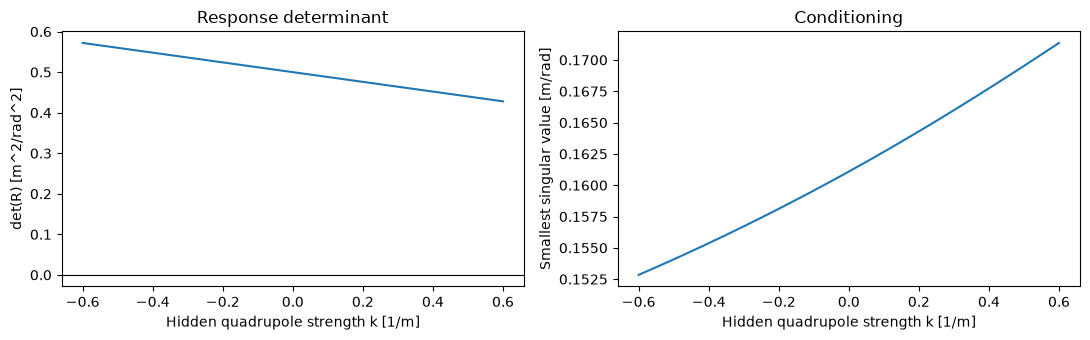

In [3]:
def analytic_response_matrix(quadrupole_strength: float, lattice: Lattice) -> np.ndarray:
    """Return the 2x2 analytic local response matrix."""
    q_transport = 1.0 - quadrupole_strength * lattice.drift_to_quad
    response_11 = lattice.drift_to_quad + (lattice.drift_to_corrector_2 + lattice.drift_to_bpm_1) * q_transport
    response_21 = response_11 + lattice.drift_to_bpm_2 * q_transport
    return np.array(
        [
            [response_11, lattice.drift_to_bpm_1],
            [response_21, lattice.drift_to_bpm_1 + lattice.drift_to_bpm_2],
        ],
        dtype=np.float64,
    )


k_scan = np.linspace(-LATTICE.k_limit, LATTICE.k_limit, 401)
determinants = np.asarray([np.linalg.det(analytic_response_matrix(k_value, LATTICE)) for k_value in k_scan])
smallest_singular_values = np.asarray(
    [np.linalg.svd(analytic_response_matrix(k_value, LATTICE), compute_uv=False)[-1] for k_value in k_scan]
)
assert np.min(np.abs(determinants)) > 0.40
assert np.min(smallest_singular_values) > 0.15
print(f"Minimum |det(R)|: {np.min(np.abs(determinants)):.3f} m^2/rad^2")
print(f"Minimum singular value: {np.min(smallest_singular_values):.3f} m/rad")

fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
axes[0].plot(k_scan, determinants)
axes[0].axhline(0.0, color="black", linewidth=0.8)
axes[0].set(xlabel="Hidden quadrupole strength k [1/m]", ylabel="det(R) [m^2/rad^2]", title="Response determinant")
axes[1].plot(k_scan, smallest_singular_values)
axes[1].set(xlabel="Hidden quadrupole strength k [1/m]", ylabel="Smallest singular value [m/rad]", title="Conditioning")
fig.tight_layout()

## Environment without Gym

Observation includes normalized BPM readings, previous action, and current kicks:
$$
s_t =
\left(
\frac{x_{\mathrm{BPM1}}}{s_{\mathrm{bpm}}},
\frac{x_{\mathrm{BPM2}}}{s_{\mathrm{bpm}}},
a_{t-1,1},
a_{t-1,2},
\frac{\theta_{t,1}}{\theta_{\max}},
\frac{\theta_{t,2}}{\theta_{\max}}
\right).
$$

Action is a bounded incremental command in $[-1, 1]^2$, mapped to kick increments.

In [4]:
BPM_SCALE: Final = 1.0e-3
OBSERVATION_CLIP: Final = 6.0
MAX_KICK_INCREMENT: Final = 8.0e-4
MAX_KICK: Final = 4.0e-3
ACTION_COST: Final = 2.0e-3
TARGET_TOLERANCE: Final = 1.0e-5
SUCCESS_BONUS: Final = 5.0
MAX_STEPS: Final = 35


class TwoCorrectorOrbitEnv:
    """Minimal environment API with reset and step methods."""

    def __init__(self, lattice: Lattice, rng_seed: int) -> None:
        self.lattice = lattice
        self.rng = np.random.default_rng(rng_seed)
        self.simulator = BeamlineSimulator(lattice)
        self.kicks = np.zeros(2, dtype=np.float64)
        self.last_action = np.zeros(2, dtype=np.float64)
        self.step_count = 0

    def _observation(self) -> np.ndarray:
        normalized = self.simulator.bpm_readings(self.kicks) / BPM_SCALE
        normalized_bpm = np.clip(normalized, -OBSERVATION_CLIP, OBSERVATION_CLIP)
        normalized_kicks = self.kicks / MAX_KICK
        return np.concatenate([normalized_bpm, self.last_action, normalized_kicks])

    def reset(self) -> np.ndarray:
        x0 = self.rng.uniform(-self.lattice.x0_limit, self.lattice.x0_limit)
        xp0 = self.rng.uniform(-self.lattice.xp0_limit, self.lattice.xp0_limit)
        quadrupole_strength = self.rng.uniform(-self.lattice.k_limit, self.lattice.k_limit)
        self.simulator.set_hidden_episode_state(x0, xp0, quadrupole_strength)
        self.kicks.fill(0.0)
        self.last_action.fill(0.0)
        self.step_count = 0
        return self._observation()

    def step(self, action: np.ndarray) -> tuple[np.ndarray, float, bool, dict]:
        clipped_action = np.clip(np.asarray(action, dtype=np.float64), -1.0, 1.0)
        self.last_action = clipped_action.copy()
        self.kicks = np.clip(self.kicks + MAX_KICK_INCREMENT * clipped_action, -MAX_KICK, MAX_KICK)
        self.step_count += 1
        readings = self.simulator.bpm_readings(self.kicks)
        normalized = readings / BPM_SCALE
        is_success = bool(np.max(np.abs(readings)) < TARGET_TOLERANCE)
        reward = -float(np.dot(normalized, normalized) + ACTION_COST * np.dot(clipped_action, clipped_action))
        if is_success:
            reward += SUCCESS_BONUS
        done = bool(is_success or self.step_count >= MAX_STEPS)
        info = {"is_success": is_success}
        return self._observation(), reward, done, info


env_probe = TwoCorrectorOrbitEnv(LATTICE, rng_seed=SEED)
observation = env_probe.reset()
print("Initial observation [BPM, previous action, normalized kicks]:", observation)
assert observation.shape == (6,)

Initial observation [BPM, previous action, normalized kicks]: [-0.40743349 -0.94265359  0.          0.          0.          0.        ]


## Response-matrix baseline

We estimate $R$ with finite differences around the current operating point:
$$
R_{:,j}\approx\frac{y(\theta+\delta e_j)-y(\theta-\delta e_j)}{2\delta}.
$$
Then solve one linear correction:
$$
\Delta\theta = -R^{-1}y.
$$

In [5]:
RESPONSE_PROBE: Final = 1.0e-6


def estimate_response_matrix(simulator: BeamlineSimulator, kicks: np.ndarray, probe: float = RESPONSE_PROBE) -> np.ndarray:
    """Estimate the local 2x2 response matrix from symmetric kick probes."""
    response = np.empty((2, 2), dtype=np.float64)
    for column in range(2):
        positive = kicks.copy()
        negative = kicks.copy()
        positive[column] += probe
        negative[column] -= probe
        response[:, column] = (simulator.bpm_readings(positive) - simulator.bpm_readings(negative)) / (2.0 * probe)
    return response


def response_matrix_correction(environment: TwoCorrectorOrbitEnv) -> tuple[np.ndarray, np.ndarray]:
    """Apply one local response-matrix correction and return before/after BPM readings."""
    before = environment.simulator.bpm_readings(environment.kicks)
    response = estimate_response_matrix(environment.simulator, environment.kicks)
    kick_change = np.linalg.solve(response, -before)
    environment.kicks = np.clip(environment.kicks + kick_change, -MAX_KICK, MAX_KICK)
    after = environment.simulator.bpm_readings(environment.kicks)
    return before, after


baseline_env = TwoCorrectorOrbitEnv(LATTICE, rng_seed=SEED + 1)
baseline_env.reset()
baseline_before, baseline_after = response_matrix_correction(baseline_env)
print("Baseline before [mm]:", 1.0e3 * baseline_before)
print("Baseline after [um]:", 1.0e6 * baseline_after)

Baseline before [mm]: [0.70273095 1.02734979]
Baseline after [um]: [2.10419346e-11 2.84958245e-11]


## NumPy SAC components

We implement a compact SAC-style learner:

- **Policy**: Gaussian $\pi_\phi(a|s)=\mathcal{N}(\mu_\phi(s),\mathrm{diag}(\sigma_\phi^2))$
- **Twin critics**: linear function approximators $Q_{\theta_1}, Q_{\theta_2}$
- **Target critics** with Polyak averaging
- **Replay buffer**

Critic target:
$$
y=r+\gamma\left(\min_i Q_{\bar\theta_i}(s',a')-\alpha\log\pi_\phi(a'|s')\right)
$$

Actor objective:
$$
J(\phi)=\mathbb{E}_{s,a\sim\pi_\phi}\left[\alpha\log\pi_\phi(a|s)-\min_i Q_{\theta_i}(s,a)\right].
$$

For a pure NumPy implementation, we use a pathwise-style deterministic policy update
based on critic action gradients:
$$
\nabla_\phi J
\approx
\mathbb{E}\left[\nabla_a Q_{\min}(s,a)\,\nabla_\phi a_\phi(s,\epsilon)\right].
$$
This keeps the implementation compact and avoids external autodiff libraries.

In [6]:
def critic_features(states: np.ndarray, actions: np.ndarray) -> np.ndarray:
    """Create polynomial features for linear Q approximators."""
    if actions.shape[1] != 2:
        raise ValueError("This implementation expects exactly two actions.")
    cross_terms = (states[:, :, None] * actions[:, None, :]).reshape(states.shape[0], -1)
    action_squares = actions**2
    state_squares = states**2
    return np.concatenate(
        [
            np.ones((states.shape[0], 1), dtype=np.float64),
            states,
            actions,
            cross_terms,
            action_squares,
            state_squares,
        ],
        axis=1,
    )


def critic_feature_dim(state_dim: int, action_dim: int) -> int:
    """Return feature size used by critic_features."""
    return 1 + state_dim + action_dim + state_dim * action_dim + action_dim + state_dim


@dataclass
class ReplayBuffer:
    """Fixed-size replay buffer for off-policy updates."""

    states: np.ndarray
    actions: np.ndarray
    rewards: np.ndarray
    next_states: np.ndarray
    dones: np.ndarray
    size: int = 0
    pointer: int = 0

    @classmethod
    def create(cls, capacity: int, state_dim: int, action_dim: int) -> "ReplayBuffer":
        return cls(
            states=np.zeros((capacity, state_dim), dtype=np.float64),
            actions=np.zeros((capacity, action_dim), dtype=np.float64),
            rewards=np.zeros(capacity, dtype=np.float64),
            next_states=np.zeros((capacity, state_dim), dtype=np.float64),
            dones=np.zeros(capacity, dtype=np.float64),
        )

    @property
    def capacity(self) -> int:
        return self.states.shape[0]

    def add(self, state: np.ndarray, action: np.ndarray, reward: float, next_state: np.ndarray, done: bool) -> None:
        self.states[self.pointer] = state
        self.actions[self.pointer] = action
        self.rewards[self.pointer] = reward
        self.next_states[self.pointer] = next_state
        self.dones[self.pointer] = float(done)
        self.pointer = (self.pointer + 1) % self.capacity
        self.size = min(self.size + 1, self.capacity)

    def sample(self, batch_size: int, rng: np.random.Generator) -> tuple[np.ndarray, ...]:
        if self.size < batch_size:
            raise ValueError("Not enough samples in replay buffer.")
        indices = rng.integers(0, self.size, size=batch_size)
        return (
            self.states[indices],
            self.actions[indices],
            self.rewards[indices],
            self.next_states[indices],
            self.dones[indices],
        )


@dataclass
class LinearCritic:
    """Linear Q approximator fitted by regularized least squares on each batch."""

    weights: np.ndarray

    @classmethod
    def create(cls, feature_dim: int, rng: np.random.Generator) -> "LinearCritic":
        return cls(weights=0.01 * rng.standard_normal(feature_dim))

    def predict(self, states: np.ndarray, actions: np.ndarray) -> np.ndarray:
        features = critic_features(states, actions)
        return features @ self.weights

    def action_gradient(self, states: np.ndarray, actions: np.ndarray) -> np.ndarray:
        """Return dQ/da for each state-action pair."""
        state_dim = states.shape[1]
        action_dim = actions.shape[1]
        if action_dim != 2:
            raise ValueError("This implementation expects exactly two actions.")

        action_start = 1 + state_dim
        cross_start = action_start + action_dim
        action_square_start = cross_start + state_dim * action_dim

        gradients = np.zeros_like(actions)
        for action_index in range(action_dim):
            gradients[:, action_index] += self.weights[action_start + action_index]
            cross_weights = self.weights[cross_start + action_index : cross_start + state_dim * action_dim : action_dim]
            gradients[:, action_index] += states @ cross_weights
            gradients[:, action_index] += 2.0 * self.weights[action_square_start + action_index] * actions[:, action_index]
        return gradients

    def fit_batch(self, states: np.ndarray, actions: np.ndarray, targets: np.ndarray, ridge: float, mix: float) -> None:
        features = critic_features(states, actions)
        if not (np.all(np.isfinite(features)) and np.all(np.isfinite(targets))):
            return
        gram = features.T @ features
        regularized = gram + ridge * np.eye(gram.shape[0], dtype=np.float64)
        rhs = features.T @ targets
        solved = scipy.linalg.solve(regularized, rhs, assume_a="pos")
        self.weights = (1.0 - mix) * self.weights + mix * solved


@dataclass
class GaussianPolicy:
    """State-affine squashed Gaussian policy with critic-gradient actor updates."""

    weight: np.ndarray
    bias: np.ndarray
    log_std: np.ndarray

    @classmethod
    def create(cls, state_dim: int, action_dim: int, rng: np.random.Generator) -> "GaussianPolicy":
        return cls(
            weight=0.05 * rng.standard_normal((action_dim, state_dim)),
            bias=np.zeros(action_dim, dtype=np.float64),
            log_std=np.full(action_dim, -1.2, dtype=np.float64),
        )

    def mean(self, states: np.ndarray) -> np.ndarray:
        return states @ self.weight.T + self.bias

    def _squash(self, pre_tanh_actions: np.ndarray) -> np.ndarray:
        return np.tanh(pre_tanh_actions)

    def deterministic_actions(self, states: np.ndarray) -> np.ndarray:
        """Return deterministic bounded actions for a batch of states."""
        return self._squash(self.mean(states))

    def sample(self, states: np.ndarray, rng: np.random.Generator) -> tuple[np.ndarray, np.ndarray]:
        mean_values = self.mean(states)
        std = np.exp(self.log_std)
        noise = rng.standard_normal(mean_values.shape)
        pre_tanh_actions = mean_values + noise * std
        actions = self._squash(pre_tanh_actions)
        log_prob = self.log_prob(states, actions, pre_tanh_actions=pre_tanh_actions)
        return actions, log_prob

    def deterministic_action(self, state: np.ndarray) -> np.ndarray:
        return self.deterministic_actions(state[None, :])[0]

    def log_prob(
        self,
        states: np.ndarray,
        actions: np.ndarray,
        pre_tanh_actions: np.ndarray | None = None,
    ) -> np.ndarray:
        mean_values = self.mean(states)
        std = np.exp(self.log_std)
        if pre_tanh_actions is None:
            clipped_actions = np.clip(actions, -0.999999, 0.999999)
            pre_tanh_actions = np.arctanh(clipped_actions)
        normalized = np.clip((pre_tanh_actions - mean_values) / std, -20.0, 20.0)
        dimension = actions.shape[1]
        gaussian_log_prob = -0.5 * (
            np.sum(normalized**2, axis=1)
            + 2.0 * np.sum(self.log_std)
            + dimension * np.log(2.0 * np.pi)
        )
        squash_correction = np.sum(np.log(1.0 - np.clip(actions**2, 0.0, 0.999999) + 1.0e-6), axis=1)
        log_prob = gaussian_log_prob - squash_correction
        return np.clip(log_prob, -80.0, 40.0)

    def update_with_action_gradient(
        self,
        states: np.ndarray,
        pre_tanh_actions: np.ndarray,
        action_gradient: np.ndarray,
        learning_rate: float,
    ) -> None:
        actions = self._squash(pre_tanh_actions)
        tanh_derivative = 1.0 - actions**2
        effective_action_gradient = np.clip(action_gradient * tanh_derivative, -20.0, 20.0)
        grad_weight = np.zeros_like(self.weight)
        grad_bias = np.zeros_like(self.bias)
        for idx in range(states.shape[0]):
            grad_weight += np.outer(effective_action_gradient[idx], states[idx])
            grad_bias += effective_action_gradient[idx]
        scale = 1.0 / states.shape[0]
        self.weight += learning_rate * scale * grad_weight
        self.bias += learning_rate * scale * grad_bias
        self.weight = np.clip(self.weight, -4.0, 4.0)
        self.bias = np.clip(self.bias, -2.0, 2.0)
        self.log_std = np.clip(self.log_std, -2.0, -0.8)


def build_oracle_dataset(
    lattice: Lattice,
    sample_count: int,
    rng_seed: int,
) -> tuple[np.ndarray, np.ndarray]:
    """Build state-action pairs from one-step response-matrix corrections."""
    environment = TwoCorrectorOrbitEnv(lattice, rng_seed=rng_seed)
    state_dim = environment.reset().shape[0]
    states = np.zeros((sample_count, state_dim), dtype=np.float64)
    actions = np.zeros((sample_count, 2), dtype=np.float64)
    for index in range(sample_count):
        state = environment.reset()
        before = environment.simulator.bpm_readings(environment.kicks)
        response = estimate_response_matrix(environment.simulator, environment.kicks)
        kick_change = np.linalg.solve(response, -before)
        action = np.clip(kick_change / MAX_KICK_INCREMENT, -1.0, 1.0)
        states[index] = state
        actions[index] = action
    return states, actions


def warmstart_policy_from_oracle(
    policy: GaussianPolicy,
    states: np.ndarray,
    actions: np.ndarray,
    ridge: float,
) -> None:
    """Initialize policy mean network by ridge regression on oracle actions."""
    state_dim = states.shape[1]
    clipped_actions = np.clip(actions, -0.999, 0.999)
    pre_tanh_targets = np.arctanh(clipped_actions)
    design = np.column_stack([states, np.ones(states.shape[0], dtype=np.float64)])
    regularized = design.T @ design + ridge * np.eye(design.shape[1], dtype=np.float64)
    solved = scipy.linalg.solve(regularized, design.T @ pre_tanh_targets, assume_a="pos")
    policy.weight = solved[:state_dim, :].T
    policy.bias = solved[state_dim, :]


def evaluate_policy_success(
    policy: GaussianPolicy,
    lattice: Lattice,
    rng_seed: int,
    episodes: int,
) -> tuple[float, float, float]:
    """Return mean return, success rate, and median final max BPM error in micrometres."""
    environment = TwoCorrectorOrbitEnv(lattice, rng_seed=rng_seed)
    returns: list[float] = []
    final_errors: list[float] = []
    successes = 0
    for _ in range(episodes):
        state = environment.reset()
        done = False
        episode_return = 0.0
        info = {"is_success": False}
        while not done:
            action = policy.deterministic_action(state)
            state, reward, done, info = environment.step(action)
            episode_return += reward
        final_bpm = environment.simulator.bpm_readings(environment.kicks)
        final_max_error = float(np.max(np.abs(final_bpm)))
        returns.append(episode_return)
        final_errors.append(final_max_error)
        successes += int(final_max_error < TARGET_TOLERANCE and info["is_success"])
    mean_return = float(np.mean(returns))
    success_rate = 100.0 * successes / episodes
    median_error_um = 1.0e6 * float(np.median(final_errors))
    return mean_return, success_rate, median_error_um

## Training loop

We use single-step episodes over a short horizon, off-policy replay, twin critics,
and Polyak target updates. To improve sample efficiency in this NumPy-only setup,
the policy mean is warm-started from a one-step response-matrix oracle dataset,
then fine-tuned by SAC-style off-policy updates.

Additional tuning in this version:
- Adaptive entropy weight $\alpha$ with a target entropy.
- Evaluation-based early stopping when success rate stops improving.

In [7]:
GAMMA: Final = 0.98
INITIAL_ALPHA: Final = 0.05
TARGET_POLICY_ENTROPY: Final = 0.4
ALPHA_LR: Final = 4.0e-4
ALPHA_MIN: Final = 5.0e-3
ALPHA_MAX: Final = 0.12
BATCH_SIZE: Final = 256
BUFFER_CAPACITY: Final = 60_000
WARMUP_STEPS: Final = 1_000
TRAIN_EPISODES: Final = 700
UPDATES_PER_STEP: Final = 1
POLYAK: Final = 0.99
CRITIC_RIDGE: Final = 1.0e-4
CRITIC_MIX: Final = 0.30
ACTOR_LR: Final = 2.0e-4
ORACLE_WARMSTART_SAMPLES: Final = 8_000
ORACLE_WARMSTART_RIDGE: Final = 1.0e-3
EARLY_STOPPING_PATIENCE_EVALS: Final = 8
EVALUATION_INTERVAL_EPISODES: Final = 50

training_env = TwoCorrectorOrbitEnv(LATTICE, rng_seed=SEED + 10)
evaluation_env = TwoCorrectorOrbitEnv(LATTICE, rng_seed=SEED + 20)
state_dim = training_env.reset().shape[0]
action_dim = 2
feature_dim = critic_feature_dim(state_dim=state_dim, action_dim=action_dim)
policy = GaussianPolicy.create(state_dim=state_dim, action_dim=action_dim, rng=RNG)
critic_1 = LinearCritic.create(feature_dim=feature_dim, rng=RNG)
critic_2 = LinearCritic.create(feature_dim=feature_dim, rng=RNG)
target_critic_1 = LinearCritic(weights=critic_1.weights.copy())
target_critic_2 = LinearCritic(weights=critic_2.weights.copy())
replay = ReplayBuffer.create(capacity=BUFFER_CAPACITY, state_dim=state_dim, action_dim=action_dim)

warmstart_states, warmstart_actions = build_oracle_dataset(
    lattice=LATTICE,
    sample_count=ORACLE_WARMSTART_SAMPLES,
    rng_seed=SEED + 123,
)
warmstart_policy_from_oracle(
    policy=policy,
    states=warmstart_states,
    actions=warmstart_actions,
    ridge=ORACLE_WARMSTART_RIDGE,
)
policy.log_std[:] = -1.6
print("Initialized policy from one-step response-matrix oracle dataset.")
warmstart_mean_return, warmstart_success_rate, warmstart_median_error_um = evaluate_policy_success(
    policy=policy,
    lattice=LATTICE,
    rng_seed=SEED + 220,
    episodes=120,
)
print(
    "Warm-start policy:",
    f"mean return={warmstart_mean_return:.2f},",
    f"success={warmstart_success_rate:.1f}%,",
    f"median error={warmstart_median_error_um:.1f} um",
)

best_policy_weight = policy.weight.copy()
best_policy_bias = policy.bias.copy()
best_policy_log_std = policy.log_std.copy()
best_success_rate = warmstart_success_rate
best_median_error_um = warmstart_median_error_um
log_alpha = float(np.log(INITIAL_ALPHA))
current_alpha = INITIAL_ALPHA
evaluations_without_improvement = 0
completed_episodes = 0

episode_returns: list[float] = []
total_steps = 0
for episode in range(TRAIN_EPISODES):
    state = training_env.reset()
    cumulative_reward = 0.0
    done = False
    while not done:
        if total_steps < WARMUP_STEPS:
            raw_action = RNG.uniform(-1.0, 1.0, size=2)
        else:
            sampled_action, _ = policy.sample(state[None, :], RNG)
            raw_action = sampled_action[0]

        action = np.clip(raw_action, -1.0, 1.0)
        next_state, reward, done, _ = training_env.step(action)
        replay.add(state, action, reward, next_state, done)
        state = next_state
        cumulative_reward += reward
        total_steps += 1

        if replay.size >= BATCH_SIZE and total_steps >= WARMUP_STEPS:
            for _ in range(UPDATES_PER_STEP):
                batch_states, batch_actions, batch_rewards, batch_next_states, batch_dones = replay.sample(BATCH_SIZE, RNG)

                next_actions, next_log_prob = policy.sample(batch_next_states, RNG)
                target_q1 = target_critic_1.predict(batch_next_states, next_actions)
                target_q2 = target_critic_2.predict(batch_next_states, next_actions)
                target_min = np.minimum(target_q1, target_q2)
                bellman_targets = batch_rewards + GAMMA * (1.0 - batch_dones) * (target_min - current_alpha * next_log_prob)
                bellman_targets = np.clip(bellman_targets, -300.0, 20.0)

                critic_1.fit_batch(
                    states=batch_states,
                    actions=batch_actions,
                    targets=bellman_targets,
                    ridge=CRITIC_RIDGE,
                    mix=CRITIC_MIX,
                )
                critic_2.fit_batch(
                    states=batch_states,
                    actions=batch_actions,
                    targets=bellman_targets,
                    ridge=CRITIC_RIDGE,
                    mix=CRITIC_MIX,
                )

                actor_mean = policy.mean(batch_states)
                actor_std = np.exp(policy.log_std)
                actor_noise = RNG.standard_normal(actor_mean.shape)
                actor_pre_tanh = actor_mean + actor_std * actor_noise
                actor_actions = np.tanh(actor_pre_tanh)

                q1_values = critic_1.predict(batch_states, actor_actions)
                q2_values = critic_2.predict(batch_states, actor_actions)
                use_critic_one = q1_values <= q2_values
                gradient_one = critic_1.action_gradient(batch_states, actor_actions)
                gradient_two = critic_2.action_gradient(batch_states, actor_actions)
                actor_action_gradient = np.where(use_critic_one[:, None], gradient_one, gradient_two)

                policy.update_with_action_gradient(
                    states=batch_states,
                    pre_tanh_actions=actor_pre_tanh,
                    action_gradient=actor_action_gradient,
                    learning_rate=ACTOR_LR,
                )

                mean_log_prob = float(np.mean(next_log_prob))
                current_entropy = -mean_log_prob
                entropy_error = TARGET_POLICY_ENTROPY - current_entropy
                log_alpha += ALPHA_LR * entropy_error
                clipped_alpha = float(np.clip(np.exp(log_alpha), ALPHA_MIN, ALPHA_MAX))
                current_alpha = clipped_alpha
                log_alpha = float(np.log(current_alpha))

                target_critic_1.weights = POLYAK * target_critic_1.weights + (1.0 - POLYAK) * critic_1.weights
                target_critic_2.weights = POLYAK * target_critic_2.weights + (1.0 - POLYAK) * critic_2.weights

    completed_episodes += 1
    episode_returns.append(cumulative_reward)
    if (episode + 1) % EVALUATION_INTERVAL_EPISODES == 0:
        _, candidate_success_rate, candidate_median_error_um = evaluate_policy_success(
            policy=policy,
            lattice=LATTICE,
            rng_seed=SEED + 330 + episode,
            episodes=80,
        )
        is_better = (
            candidate_success_rate > best_success_rate
            or (
                np.isclose(candidate_success_rate, best_success_rate)
                and candidate_median_error_um < best_median_error_um
            )
        )
        if is_better:
            best_success_rate = candidate_success_rate
            best_median_error_um = candidate_median_error_um
            best_policy_weight = policy.weight.copy()
            best_policy_bias = policy.bias.copy()
            best_policy_log_std = policy.log_std.copy()
            evaluations_without_improvement = 0
        else:
            evaluations_without_improvement += 1
        print(
            f"Episode {episode + 1:4d}:",
            f"candidate success={candidate_success_rate:.1f}%,",
            f"candidate median error={candidate_median_error_um:.1f} um,",
            f"best success={best_success_rate:.1f}%,",
            f"best median error={best_median_error_um:.1f} um,",
            f"alpha={current_alpha:.4f},",
            f"stale_evals={evaluations_without_improvement}",
        )
        if evaluations_without_improvement >= EARLY_STOPPING_PATIENCE_EVALS:
            print("Early stopping triggered by stagnant evaluation success rate.")
            break

print("Training episodes:", completed_episodes)
print("Replay size:", replay.size)
print(f"Final adaptive alpha: {current_alpha:.4f}")
policy.weight = best_policy_weight
policy.bias = best_policy_bias
policy.log_std = best_policy_log_std
print("Restored best policy snapshot for final evaluation.")

Initialized policy from one-step response-matrix oracle dataset.
Warm-start policy: mean return=-5.06, success=15.8%, median error=39.7 um
Episode   50: candidate success=2.5%, candidate median error=387.0 um, best success=15.8%, best median error=39.7 um, alpha=0.1200, stale_evals=1
Episode  100: candidate success=15.0%, candidate median error=262.2 um, best success=15.8%, best median error=39.7 um, alpha=0.1200, stale_evals=2
Episode  150: candidate success=55.0%, candidate median error=9.5 um, best success=55.0%, best median error=9.5 um, alpha=0.1200, stale_evals=0
Episode  200: candidate success=57.5%, candidate median error=9.4 um, best success=57.5%, best median error=9.4 um, alpha=0.1200, stale_evals=0
Episode  250: candidate success=41.2%, candidate median error=24.0 um, best success=57.5%, best median error=9.4 um, alpha=0.1200, stale_evals=1
Episode  300: candidate success=26.2%, candidate median error=37.5 um, best success=57.5%, best median error=9.4 um, alpha=0.1200, stal

## Evaluation

We evaluate with deterministic policy action $a=\mu_\phi(s)$ (clipped to $[-1,1]$).

Evaluation mean return: -1.01 +/- 5.91
Success rate: 51.3%
Median final max BPM error: 10.0 um


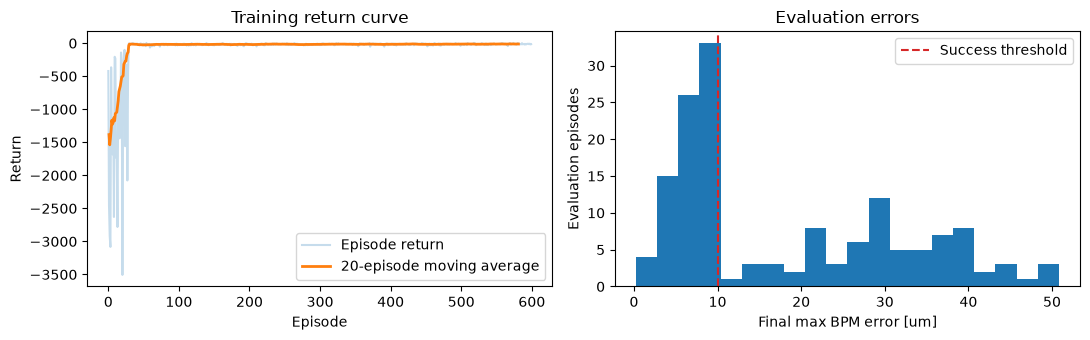

In [8]:
EVAL_EPISODES: Final = 150
evaluation_returns: list[float] = []
final_max_errors: list[float] = []
success_count = 0

for _ in range(EVAL_EPISODES):
    state = evaluation_env.reset()
    done = False
    episode_return = 0.0
    while not done:
        action = policy.deterministic_action(state)
        state, reward, done, info = evaluation_env.step(action)
        episode_return += reward
    final_bpm = evaluation_env.simulator.bpm_readings(evaluation_env.kicks)
    final_max_error = float(np.max(np.abs(final_bpm)))
    final_max_errors.append(final_max_error)
    evaluation_returns.append(episode_return)
    success_count += int(final_max_error < TARGET_TOLERANCE and info["is_success"])

print(f"Evaluation mean return: {np.mean(evaluation_returns):.2f} +/- {np.std(evaluation_returns):.2f}")
print(f"Success rate: {100.0 * success_count / EVAL_EPISODES:.1f}%")
print(f"Median final max BPM error: {1.0e6 * np.median(final_max_errors):.1f} um")


def moving_average(values: list[float], window: int = 20) -> np.ndarray:
    """Return trailing moving average."""
    if len(values) < 1:
        return np.asarray([], dtype=np.float64)
    window_size = min(window, len(values))
    kernel = np.ones(window_size, dtype=np.float64) / window_size
    return np.convolve(np.asarray(values, dtype=np.float64), kernel, mode="valid")


smoothed_returns = moving_average(episode_returns, window=20)
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
axes[0].plot(episode_returns, alpha=0.25, label="Episode return")
axes[0].plot(
    np.arange(len(smoothed_returns)) + 1,
    smoothed_returns,
    linewidth=2.0,
    label="20-episode moving average",
)
axes[0].set(xlabel="Episode", ylabel="Return", title="Training return curve")
axes[0].legend()
axes[1].hist(1.0e6 * np.asarray(final_max_errors), bins=20)
axes[1].axvline(1.0e6 * TARGET_TOLERANCE, color="tab:red", linestyle="--", label="Success threshold")
axes[1].set(xlabel="Final max BPM error [um]", ylabel="Evaluation episodes", title="Evaluation errors")
axes[1].legend()
fig.tight_layout()

## Before/after trajectory on one held-out episode

The policy observes BPM values, previous action, and current normalized kicks at each step.
Full trajectory is shown only for visualization.

Final BPM readings after SAC [um]: [ 4.31303125 33.35868017]


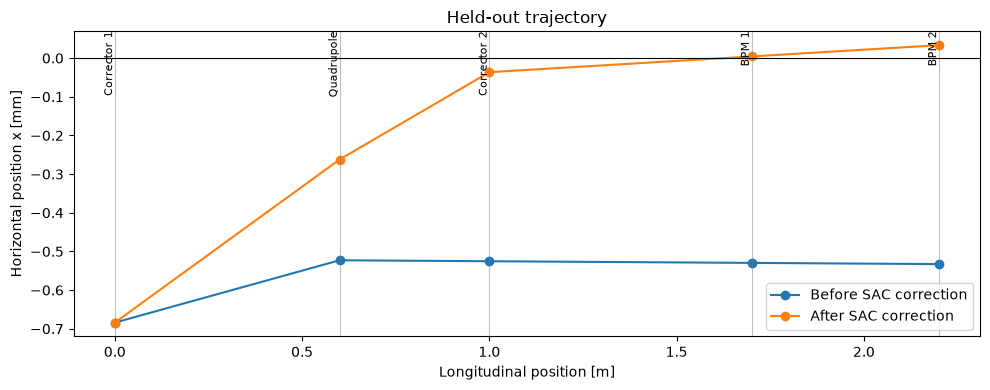

In [9]:
trajectory_env = TwoCorrectorOrbitEnv(LATTICE, rng_seed=20_026)
state = trajectory_env.reset()
positions, orbit_before = trajectory_env.simulator.trajectory(trajectory_env.kicks)
done = False
while not done:
    action = policy.deterministic_action(state)
    state, _, done, _ = trajectory_env.step(action)
_, orbit_after = trajectory_env.simulator.trajectory(trajectory_env.kicks)

element_positions = positions
element_names = ["Corrector 1", "Quadrupole", "Corrector 2", "BPM 1", "BPM 2"]
fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(positions, 1.0e3 * orbit_before, marker="o", label="Before SAC correction")
ax.plot(positions, 1.0e3 * orbit_after, marker="o", label="After SAC correction")
for element_position, element_name in zip(element_positions, element_names):
    ax.axvline(element_position, color="gray", linewidth=0.8, alpha=0.5)
    ax.text(element_position, ax.get_ylim()[1], element_name, rotation=90, va="top", ha="right", fontsize=8)
ax.axhline(0.0, color="black", linewidth=0.8)
ax.set(xlabel="Longitudinal position [m]", ylabel="Horizontal position x [mm]", title="Held-out trajectory")
ax.legend()
fig.tight_layout()
print("Final BPM readings after SAC [um]:", 1.0e6 * orbit_after[-2:])

## Notes and limitations

- This is a compact educational implementation, not a full industrial SAC stack.
- Actor update uses critic action gradients through a tanh-squashed Gaussian policy.
- Critics are linear in engineered features; this keeps dependencies minimal.
- The machine model is linear, noiseless, and horizontal-only.
- For more realism, add noise, calibration drift, constraints, and temporal history.